# Dynamic Counting Modeling Choices

This notebook explore several ways on how (not) to resolve the legislative side in reference networks, and analyzed their impacts on a standard metric (centrality).

1. No limitation of node set

## 0. Setup

In [ ]:
# Imports

from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

from network_pluralism.access.resolved import to_level
from network_pluralism.access.utils.files import load_matrix
from network_pluralism.access.utils.labels import (
    get_well_written_sections,
    get_well_written_section,
)
from network_pluralism.access.utils.df import return_top_n
from network_pluralism.setup.paths import COMPUTATION_PATH, PREPROCESSED_DATA_DECISIONS


In [3]:
# Matplotlib Config


def set_rcParams(**kwargs):
    params = {
        "pdf.fonttype": 42,
        "text.usetex": False,
        "font.family": "serif",
        "text.latex.preamble": r"\usepackage{amssymb}\usepackage{amsmath}",
        "font.size": 16,
        "legend.fontsize": 14,
        "legend.title_fontsize": 16,
        "axes.labelsize": 18,
        "xtick.labelsize": 16,
        "ytick.labelsize": 16,
        "axes.spines.right": False,
        "axes.spines.top": False,
        "legend.columnspacing": 1.0,
        "legend.frameon": False,
        "lines.linewidth": 3,
    }
    for param in kwargs:
        if param in plt.rcParams.keys():
            params[param] = kwargs[param]
    for k, v in params.items():
        plt.rcParams[k] = v


set_rcParams()

In [ ]:
EXPORT_PATH = Path("../../figures_and_results/dynamic_counting")
EXPORT_PATH.mkdir(exist_ok=True)

In [ ]:
matrix, rows_mapping, col_mapping = to_level(0, 1)

In [ ]:
levels_df = pd.read_parquet(COMPUTATION_PATH / "levels.parquet").set_index("sem_id")[
    ["level"]
]
levels_df.head()

,level
sem_id,
euvtrg_1,1
euvtrg_2,1
euvtrg_3,1
euvtrg_3_1,2
euvtrg_3_2,2


In [262]:
def get_aggregation_matrix_at_level(source_level: int):

    aggregation_matrix, am_rows, am_cols = load_matrix(
        name=f"statutes_level_{source_level}"
    )
    row_labels = list(am_rows.keys())
    col_labels = list(am_cols.keys())

    coo = aggregation_matrix.tocoo()
    edge_list_df = pd.DataFrame(
        {
            "source": [row_labels[i] for i in coo.row],
            "target": [col_labels[j] for j in coo.col],
            "weight": coo.data,
        }
    )
    return edge_list_df

edge_list_df = pd.DataFrame()
for i in range(1,5):
    edge_list_df = pd.concat([edge_list_df,get_aggregation_matrix_at_level(i)])
edge_list_df.drop_duplicates(subset=['source','target'],inplace=True)

### No dynamic Counting

In [152]:
occurrences_df = pd.read_pickle(
    PREPROCESSED_DATA_DECISIONS / "matched_numerical_ids.pkl"
)
occurrences_df.head()

,Unnamed: 0,court,panel,decision,paragraph,pos,semantical_id,start,end,item,level,type,UUID
0,0,BPatG,BPatG_25. Senat,25 W (pat) 508/19,25 W (pat) 508/19_15,0,markeng_8_2_1,292.0,308.0,markeng_8_2_1,3,0,42064170535519776492744549313932832938
1,1,BPatG,BPatG_25. Senat,25 W (pat) 508/19,25 W (pat) 508/19_22,0,markeng_8_2_1,37.0,53.0,markeng_8_2_1,3,0,42064170535519776492744549313932832938
2,3,BPatG,BPatG_25. Senat,25 W (pat) 216/09,25 W (pat) 216/09_3,0,markeng_54_2,96.0,114.0,markeng_54_2,2,0,242215549959440275685037571880796361276
3,4,BPatG,BPatG_25. Senat,25 W (pat) 508/19,25 W (pat) 508/19_21,1,markeng_8_2_1,371.0,387.0,markeng_8_2_1,3,0,42064170535519776492744549313932832938
4,5,BPatG,BPatG_25. Senat,25 W (pat) 508/19,25 W (pat) 508/19_21,0,markeng_64_6,9.0,32.0,markeng_64_6,2,0,317653909489634983075549076632237719954


In [277]:
top_20_raw = (
    occurrences_df.groupby("item")
    .count()[["type"]]
    .rename({"type": "count"}, axis=1)
    .sort_values(by="count", ascending=False)
    .head(20)
    .join(levels_df)
)
top_20_raw

,count,level
item,,
gg_3_1,14742,2
markeng_8_2_1,12053,3
gg_103_1,10122,2
markeng_8_2_2,8755,3
gg_2_1,7913,2
vwgo_132_2_1,6879,3
gg_19_4,6688,2
gg_12_1,6150,2
zpo_97_1,6100,2


In [45]:
top_20_only_level_1 = (
    occurrences_df.query("level==1")
    .groupby("item")
    .count()[["type"]]
    .rename({"type": "count"}, axis=1)
    .sort_values(by="count", ascending=False)
    .head(20)
    .join(levels_df)
)

In [ ]:
top_20_only_level_2 = (
    occurrences_df.query("level==2")
    .groupby("item")
    .count()[["type"]]
    .rename({"type": "count"}, axis=1)
    .sort_values(by="count", ascending=False)
    .head(20)
)

In [ ]:
top_20_only_level_3 = (
    occurrences_df.query("level==3")
    .groupby("item")
    .count()[["type"]]
    .rename({"type": "count"}, axis=1)
    .sort_values(by="count", ascending=False)
    .head(20)
)
top_20_only_level_3

,count
item,
markeng_8_2_1,12053
markeng_8_2_2,8755
vwgo_132_2_1,6879
vwgo_132_2_3,3801
sgg_160_2_3,3289
fgo_115_2_1,3008
fgo_115_2_2,2897
vwgo_132_2_2,2738
fgo_115_2_3,2694


In [52]:
top_20_only_level_3 = (
    occurrences_df.query("level==4")
    .groupby("item")
    .count()[["type"]]
    .rename({"type": "count"}, axis=1)
    .sort_values(by="count", ascending=False)
    .head(20)
)
top_20_only_level_3

,count
item,
ao_1977_180_1_2_a,565
zpo_551_3_2_b,266
zpo_551_3_2_a,223
ustg_1980_13_1_1_a,182
ao_1977_172_1_2_a,159
fgo_120_3_2_a,146
energiestg_51_1_1_a,130
arbgg_2_1_3_a,74
ao_1977_180_1_2_b,74


In [51]:
top_20_only_level_1_and_2 = occurrences_df.query("level in [1,2]").groupby("item").count()[["type"]].rename(
    {"type": "count"}, axis=1
).sort_values(by="count", ascending=False).head(20).join(levels_df)
top_20_only_level_1_and_2

,count,level
item,,
gg_3_1,14742,2
gg_103_1,10122,2
gg_2_1,7913,2
gg_19_4,6688,2
gg_12_1,6150,2
zpo_97_1,6100,2
stpo_349_2,6029,2
gg_20_3,5356,2
vwgo_154_2,5212,2


In [53]:
top_20_only_level_2_and_3 = occurrences_df.query("level in [3,2]").groupby("item").count()[["type"]].rename(
    {"type": "count"}, axis=1
).sort_values(by="count", ascending=False).head(20).join(levels_df)
top_20_only_level_2_and_3

,count,level
item,,
gg_3_1,14742,2
markeng_8_2_1,12053,3
gg_103_1,10122,2
markeng_8_2_2,8755,3
gg_2_1,7913,2
vwgo_132_2_1,6879,3
gg_19_4,6688,2
gg_12_1,6150,2
zpo_97_1,6100,2


## With dynamic counting

In [54]:
matrix, rows_mapping, col_mapping = to_level(0,1)

Out Matrix of shape (8, 93645)


In [57]:
top_20_resolved_to_level_1 = return_top_n(matrix, rows_mapping, col_mapping, axis=0,top_n=20)
top_20_resolved_to_level_1

,count
markeng_8,25054.0
gg_3,17785.0
vwgo_132,15521.0
gg_2,12713.0
gg_103,11943.0
fgo_115,9911.0
gg_20,8388.0
bgb_307,7879.0
zpo_563,7872.0
stpo_349,7764.0


In [58]:
matrix, rows_mapping, col_mapping = to_level(0, 2)

Out Matrix of shape (8, 268552)


In [59]:
top_20_resolved_to_level_2 = return_top_n(matrix, rows_mapping, col_mapping, axis=0,top_n=20)
top_20_resolved_to_level_2

,count
markeng_8_2,23665.500000
gg_3_1,15181.333333
vwgo_132_2,15144.666667
gg_103_1,10350.666667
fgo_115_2,9710.333333
gg_2_1,8348.000000
sgg_160_2,6999.666667
gg_19_4,6816.750000
gg_12_1,6589.333333
zpo_97_1,6182.000000


In [72]:
matrix, rows_mapping, col_mapping = to_level(0, 3)

Out Matrix of shape (8, 389518)


In [73]:
top_20_resolved_to_level_3 = return_top_n(
    matrix, rows_mapping, col_mapping, axis=0, top_n=20
)
top_20_resolved_to_level_3.join(levels_df)

,count,level
gg_3_1,15181.333333,2
markeng_8_2_1,12086.535714,3
gg_103_1,10350.666667,2
markeng_8_2_2,8788.535714,3
gg_2_1,8348.000000,2
vwgo_132_2_1,7454.555556,3
gg_19_4,6816.750000,2
gg_12_1,6589.333333,2
zpo_97_1,6182.000000,2
stpo_349_2,6034.800000,2


In [74]:
top_20_only_level_2

,count
item,
gg_3_1,14742
gg_103_1,10122
gg_2_1,7913
gg_19_4,6688
gg_12_1,6150
zpo_97_1,6100
stpo_349_2,6029
gg_20_3,5356
vwgo_154_2,5212


In [81]:
top_20_only_level_2.loc['gg_3_1','count']

np.int64(14742)

In [ ]:
top_20_resolved_to_level_1.rank(ascending=False)

,count
markeng_8,1.0
gg_3,2.0
vwgo_132,3.0
gg_2,4.0
gg_103,5.0
fgo_115,6.0
gg_20,7.0
bgb_307,8.0
zpo_563,9.0
stpo_349,10.0


In [106]:
top_20_only_level_1

,count,level
item,,
bgb_242,4620,1
bgb_826,4089,1
stgb_64,2461,1
sgg_163,2432,1
sgg_193,2400,1
bgb_133,2388,1
bgb_134,2261,1
sgg_169,2245,1
zpo_561,2202,1


In [119]:
d = []
ranks = {0: top_20_resolved_to_level_1, 5: top_20_only_level_1}

ranks = {k: v.rank(ascending=False) for k, v in ranks.items()}

indices = []
for rank_key, rank in ranks.items():
    indices.extend(rank.index)
for norm in indices:
    item = {"Name": [], "rank": [], "min_ref": []}

    for rank_key, rank in ranks.items():
        if norm in rank.index:
            item["Name"].append(norm)
            item["rank"].append(rank.loc[norm, "count"])
            item["min_ref"].append(rank_key)
    d.append(item)
d

[{'Name': ['markeng_8'], 'rank': [np.float64(1.0)], 'min_ref': [0]},
 {'Name': ['gg_3'], 'rank': [np.float64(2.0)], 'min_ref': [0]},
 {'Name': ['vwgo_132'], 'rank': [np.float64(3.0)], 'min_ref': [0]},
 {'Name': ['gg_2'], 'rank': [np.float64(4.0)], 'min_ref': [0]},
 {'Name': ['gg_103'], 'rank': [np.float64(5.0)], 'min_ref': [0]},
 {'Name': ['fgo_115'], 'rank': [np.float64(6.0)], 'min_ref': [0]},
 {'Name': ['gg_20'], 'rank': [np.float64(7.0)], 'min_ref': [0]},
 {'Name': ['bgb_307'], 'rank': [np.float64(8.0)], 'min_ref': [0]},
 {'Name': ['zpo_563'], 'rank': [np.float64(9.0)], 'min_ref': [0]},
 {'Name': ['stpo_349'], 'rank': [np.float64(10.0)], 'min_ref': [0]},
 {'Name': ['gg_19'], 'rank': [np.float64(11.0)], 'min_ref': [0]},
 {'Name': ['gg_12'], 'rank': [np.float64(12.0)], 'min_ref': [0]},
 {'Name': ['vwgo_154'], 'rank': [np.float64(13.0)], 'min_ref': [0]},
 {'Name': ['sgg_160'], 'rank': [np.float64(14.0)], 'min_ref': [0]},
 {'Name': ['fgo_126'], 'rank': [np.float64(15.0)], 'min_ref': [0]

/var/folders/8k/r3s46h0143vflzq6wy9_001r0000gp/T/ipykernel_57582/1619147050.py:27: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


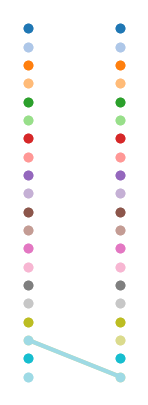

In [123]:
from itertools import cycle

greyed_1 = []
fig, ax = plt.subplots(figsize=(3, 5))

color_cycle = plt.get_cmap("tab20").__dict__["colors"]
colors = cycle(color_cycle)
ax.set_aspect("equal")
for element in d:
    element_name = element["Name"][0]
    x = [e + 1 for e in element["min_ref"]]
    y = element["rank"]

    color = next(colors) if element_name not in greyed_1 else "lightgrey"

    ax.plot(x, y, "-", color=color)  # just the line
    ax.plot(
        [x[0], x[-1]],
        [y[0], y[-1]],
        "o",
        markerfacecolor=color,
        markeredgecolor=color,
    )
    ax.set_ylim(21, 0)
    ax.set_xlim(0, 7)
    ax.set_axis_off()
fig.show()
# plt.savefig(EXPORT_PATH / "pairwise_comparison_1.pdf", dpi=600, transparent=True)

In [126]:
def plot_ranks(ranks: dict[int, pd.DataFrame], is_ranked: bool = False):
    d = []
    #ranks = {0: top_20_resolved_to_level_1, 5: top_20_only_level_1}

    ranks = {k: v.rank(ascending=False) for k, v in ranks.items()}

    indices = []
    for rank_key, rank in ranks.items():
        indices.extend(rank.index)
    for norm in indices:
        item = {"Name": [], "rank": [], "min_ref": []}

        for rank_key, rank in ranks.items():
            if norm in rank.index:
                item["Name"].append(norm)
                item["rank"].append(rank.loc[norm, "count"])
                item["min_ref"].append(rank_key)
        d.append(item)
    from itertools import cycle

    greyed_1 = []
    fig, ax = plt.subplots(figsize=(3, 5))

    color_cycle = plt.get_cmap("tab20").__dict__["colors"]
    colors = cycle(color_cycle)
    ax.set_aspect("equal")
    for element in d:
        element_name = element["Name"][0]
        x = [e + 1 for e in element["min_ref"]]
        y = element["rank"]

        color = next(colors) if element_name not in greyed_1 else "lightgrey"

        ax.plot(x, y, "-", color=color)  # just the line
        ax.plot(
            [x[0], x[-1]],
            [y[0], y[-1]],
            "o",
            markerfacecolor=color,
            markeredgecolor=color,
        )
        ax.set_ylim(21, 0)
        ax.set_xlim(0, 7)
        ax.set_axis_off()
    fig.show()

/var/folders/8k/r3s46h0143vflzq6wy9_001r0000gp/T/ipykernel_57582/3264753424.py:45: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


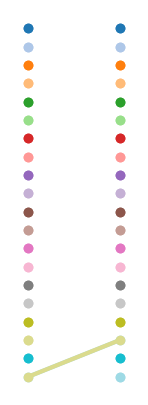

In [ ]:
plot_ranks(ranks={0: top_20_only_level_1, 5: top_20_resolved_to_level_1})

In [136]:
top_20_resolved_to_level_2

,count
markeng_8_2,23665.500000
gg_3_1,15181.333333
vwgo_132_2,15144.666667
gg_103_1,10350.666667
fgo_115_2,9710.333333
gg_2_1,8348.000000
sgg_160_2,6999.666667
gg_19_4,6816.750000
gg_12_1,6589.333333
zpo_97_1,6182.000000


In [137]:
top_20_only_level_2

,count
item,
gg_3_1,14742
gg_103_1,10122
gg_2_1,7913
gg_19_4,6688
gg_12_1,6150
zpo_97_1,6100
stpo_349_2,6029
gg_20_3,5356
vwgo_154_2,5212


In [140]:
top_20_only_level_3

,count
item,
ao_1977_180_1_2_a,565
zpo_551_3_2_b,266
zpo_551_3_2_a,223
ustg_1980_13_1_1_a,182
ao_1977_172_1_2_a,159
fgo_120_3_2_a,146
energiestg_51_1_1_a,130
arbgg_2_1_3_a,74
ao_1977_180_1_2_b,74


In [143]:
top_20_resolved_to_level_3.join(top_20_only_level_1_and_2)

ValueError: columns overlap but no suffix specified: Index(['count'], dtype='object')

/var/folders/8k/r3s46h0143vflzq6wy9_001r0000gp/T/ipykernel_57582/3264753424.py:45: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


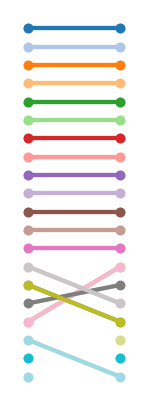

In [144]:
plot_ranks(ranks={0: top_20_raw, 5: top_20_resolved_to_level_3})

## Show

In [156]:
top_20_raw_table = top_20_raw.copy()
top_20_raw_table.index = get_well_written_sections(top_20_raw.index).values()
top_20_raw_table

,count,level
Art. 3 Abs. 1 GG,14742,2
§ 8 Abs. 2 Nr. 1 MarkenG,12053,3
Art. 103 Abs. 1 GG,10122,2
§ 8 Abs. 2 Nr. 2 MarkenG,8755,3
Art. 2 Abs. 1 GG,7913,2
§ 132 Abs. 2 Nr. 1 VwGO,6879,3
Art. 19 Abs. 4 GG,6688,2
Art. 12 Abs. 1 GG,6150,2
§ 97 Abs. 1 ZPO,6100,2
§ 349 Abs. 2 StPO,6029,2


In [364]:
pd.DataFrame().to_latex(
    columns=[
       rf"{i}" for i in  top_20_raw_table.index
    ]
)

'\\begin{tabular}{l}\n\\toprule\n\\midrule\n\\bottomrule\n\\end{tabular}\n'

In [366]:
top_20_raw_table

,count,level
Art. 3 Abs. 1 GG,14742,2
§ 8 Abs. 2 Nr. 1 MarkenG,12053,3
Art. 103 Abs. 1 GG,10122,2
§ 8 Abs. 2 Nr. 2 MarkenG,8755,3
Art. 2 Abs. 1 GG,7913,2
§ 132 Abs. 2 Nr. 1 VwGO,6879,3
Art. 19 Abs. 4 GG,6688,2
Art. 12 Abs. 1 GG,6150,2
§ 97 Abs. 1 ZPO,6100,2
§ 349 Abs. 2 StPO,6029,2


In [ ]:
latex = (
    top_20_raw_table
    .reset_index(names="Section")  # move index → column
    .rename(columns={
        "Section": r"\textbf{Law}",
        "count": r"\textbf{Count}",
        "level": r"\textbf{Level}",
    })
    .to_latex(
        '/Users/pundert1/Documents/papers/np_revision/network_pluralism_manuscript/revision/tables/raw.tex'
        ,index=False, escape=False)
)
latex

Present: level
- Statute ID
- Level Depth
- Number of references that come from below
- Number of references that come from above
- Number of direct citations
- Rank in current set up
- Rank_direct_citations

In [221]:
matrix, rows_mapping, col_mapping = to_level(0, 1)

Out Matrix of shape (8, 93645)


In [ ]:
edge_list_df = edge_list_df.query(f'target=="bgb_242"')

,source,target,weight
6034,bgb_242,bgb_242,1


In [ ]:
def get_parent_references(sem_id: str, recursive: bool = True, relative: bool = True):
    """gets number of references made to a"""
    refs = 0
    parent_lookup_df = edge_list_df.query(f'target=="{sem_id}"')
    if parent_lookup_df.empty:
        return refs
    else:
        parent = parent_lookup_df.iloc[0]["source"]
        if sem_id == parent:
            return 0
        refs_to_parent = occurrences_df.query(f"item=='{parent}'").__len__()

        if relative:
            num_of_children = edge_list_df.query(f'source=="{parent}"').__len__()
            refs += refs_to_parent / num_of_children
        if recursive:
            refs += get_parent_references(
                parent, recursive=recursive, relative=relative
            )
    return refs


In [278]:
def get_children_references(sem_id: str, recursive: bool = True, relative: bool = True):
    """gets number of references made to a"""
    refs = 0
    children_lookup_df = edge_list_df.query(f'source=="{sem_id}"')
    if children_lookup_df.empty:
        return refs
    else:
        children = children_lookup_df["target"]
        if sem_id in children.to_list():
            # print(f'{sem_id} is in {children}')
            return 0
        for c in children:
            # print(c)
            refs_to_child = occurrences_df.query(f"item=='{c}'").__len__()

            # if relative:
            #     num_of_children = edge_list_df.query(f'source=="{parent}"').__len__()
            #     refs += refs_to_parent / num_of_children
            refs += refs_to_child
            if recursive:
                refs += get_children_references(
                    c, recursive=recursive, relative=relative
                )
    return refs


assert get_children_references("bgb_242") == 0
assert get_children_references("markeng_8") != 0

In [279]:
edge_list_df.query(f'source=="markeng_8"')

,source,target,weight
185475,markeng_8,markeng_8_2,1
185476,markeng_8,markeng_8_4,1
185477,markeng_8,markeng_8_1,1
185478,markeng_8,markeng_8_3,1


In [280]:
def get_num_of_direct_citations(sem_id):
    return occurrences_df.query(f"item=='{sem_id}'").__len__()

In [ ]:
def present_resolved_table(level: int = 2):
    matrix, rows_mapping, col_mapping = to_level(0, level)

    df = return_top_n(matrix, rows_mapping, col_mapping, axis=0, top_n=20).join(
        levels_df
    )
    df["is_from_higher_level"] = df["level"] < level
    df["is_from_higher_level"] = df["is_from_higher_level"].map(lambda x: "Yes" if x else "No")
    df["count_rounded"] = round(df["count"])

    # get references from higher and lower levels
    df["from_higher"] = df.index.map(get_parent_references)
    df["from_higher_share"] = round(df["from_higher"] / df["count"], 4) * 100

    df["from_lower"] = df.index.map(get_children_references)
    df["from_lower_share"] = round(df["from_lower"] / df["count"], 4) * 100

    df["direct_citations"] = df.index.map(get_num_of_direct_citations)
    df["direct_citations_share"] = round(df["direct_citations"] / df["count"], 4) * 100

    df["Section"] = df.index.map(get_well_written_section)
    return df


df = present_resolved_table(level=2)
df

Out Matrix of shape (8, 268552)
markeng_8_2
rec
markeng_8
gg_3_1
rec
gg_3
vwgo_132_2
rec
vwgo_132
gg_103_1
rec
gg_103
fgo_115_2
rec
fgo_115
gg_2_1
rec
gg_2
sgg_160_2
rec
sgg_160
gg_19_4
rec
gg_19
gg_12_1
rec
gg_12
zpo_97_1
rec
zpo_97
stpo_349_2
rec
stpo_349
gg_20_3
rec
gg_20
vwgo_154_2
rec
vwgo_154
bgb_823_2
rec
bgb_823
gg_14_1
rec
gg_14
bgb_307_1
rec
bgb_307
bgb_242
zpo_563_1
rec
zpo_563
gg_2_2
rec
gg_2
vwgo_133_3
rec
vwgo_133


,count,level,is_from_higher_level,count_rounded,from_higher,from_higher_share,from_lower,from_lower_share,direct_citations,direct_citations_share,law
markeng_8_2,23665.500000,2,No,23666.0,124.500000,0.53,23196,98.02,345,1.46,§ 8 Abs. 2 MarkenG
gg_3_1,15181.333333,2,No,15181.0,354.333333,2.33,0,0.00,14742,97.11,3 Abs. 1 GG
vwgo_132_2,15144.666667,2,No,15145.0,149.666667,0.99,13418,88.60,1577,10.41,§ 132 Abs. 2 VwGO
gg_103_1,10350.666667,2,No,10351.0,52.666667,0.51,0,0.00,10122,97.79,103 Abs. 1 GG
fgo_115_2,9710.333333,2,No,9710.0,77.333333,0.80,8599,88.56,1034,10.65,§ 115 Abs. 2 FGO
gg_2_1,8348.000000,2,No,8348.0,118.000000,1.41,0,0.00,7913,94.79,2 Abs. 1 GG
sgg_160_2,6999.666667,2,No,7000.0,11.666667,0.17,6486,92.66,502,7.17,§ 160 Abs. 2 SGG
gg_19_4,6816.750000,2,No,6817.0,7.750000,0.11,0,0.00,6688,98.11,19 Abs. 4 GG
gg_12_1,6589.333333,2,No,6589.0,354.000000,5.37,0,0.00,6150,93.33,12 Abs. 1 GG
zpo_97_1,6182.000000,2,No,6182.0,82.000000,1.33,0,0.00,6100,98.67,§ 97 Abs. 1 ZPO


In [382]:
def export_tabular(df, path=None):
    df = df.copy()

    # Move index into column
    df = df.reset_index()
    df = df.rename(columns={"index": "Section"})  # or whatever your index name is

    # Rounding
    df["count_rounded"] = df["count_rounded"].round(0).astype(int)

    share_cols = [
        "from_higher_share",
        "direct_citations_share",
        "from_lower_share"
    ]
    df[share_cols] = df[share_cols].round(2)

    # Select columns
    df_out = df[[
        "Section",
        "count_rounded",
        "from_higher_share",
        "direct_citations_share",
        "from_lower_share",
        "is_from_higher_level"
    ]].copy()

    # MultiIndex columns (now INCLUDING Law)
    df_out.columns = pd.MultiIndex.from_tuples([
        ("", r"\textbf{Law}"),
        ("", r"\textbf{Count}"),
        (r"\textbf{Share in \%}", r"\textbf{H}"),
        (r"\textbf{Share in \%}", r"\textbf{D}"),
        (r"\textbf{Share in \%}", r"\textbf{L}"),
        ("", r"\textbf{P}")
    ])

    # Format
    styler = df_out.style.format({
        (r"\textbf{Share in \%}", r"\textbf{H}"): "{:.2f}",
        (r"\textbf{Share in \%}", r"\textbf{D}"): "{:.2f}",
        (r"\textbf{Share in \%}", r"\textbf{L}"): "{:.2f}",
    }).hide(axis="index") 
    

    latex = styler.to_latex(
        hrules=True,
        multicol_align="c",
    )

    # Optional alignment tweak
    latex = latex.replace(
        "\\begin{tabular}{llllll}",
        "\\begin{tabular}{lrrrrl}"
    )

    if path:
        with open(path, "w") as f:
            f.write(latex)

    return latex

In [383]:
cleaned = present_resolved_table(level=2)[
    [
        "count_rounded",
        "Section",
        "from_higher_share",
        "direct_citations_share",
        "from_lower_share",
        "is_from_higher_level",
    ]
].set_index("Section")
print(
    export_tabular(
        cleaned,
        path="/Users/pundert1/Documents/papers/np_revision/network_pluralism_manuscript/revision/tables/level_2.tex",
    )
)

Out Matrix of shape (8, 268552)
markeng_8_2
rec
markeng_8
gg_3_1
rec
gg_3
vwgo_132_2
rec
vwgo_132
gg_103_1
rec
gg_103
fgo_115_2
rec
fgo_115
gg_2_1
rec
gg_2
sgg_160_2
rec
sgg_160
gg_19_4
rec
gg_19
gg_12_1
rec
gg_12
zpo_97_1
rec
zpo_97
stpo_349_2
rec
stpo_349
gg_20_3
rec
gg_20
vwgo_154_2
rec
vwgo_154
bgb_823_2
rec
bgb_823
gg_14_1
rec
gg_14
bgb_307_1
rec
bgb_307
bgb_242
zpo_563_1
rec
zpo_563
gg_2_2
rec
gg_2
vwgo_133_3
rec
vwgo_133


KeyError: "['Section'] not in index"

In [ ]:
cleaned = present_resolved_table(level=1)[
    [
        "count_rounded",
        "Section",
        "from_higher_share",
        "direct_citations_share",
        "from_lower_share",
        "is_from_higher_level",
    ]
].set_index("Section")
print(
    export_tabular(
        cleaned,
        path="/Users/pundert1/Documents/papers/np_revision/network_pluralism_manuscript/revision/tables/level_1.tex",
    )
)

Out Matrix of shape (8, 93645)
markeng_8
gg_3
vwgo_132
gg_2
gg_103
fgo_115
gg_20
bgb_307
zpo_563
stpo_349
gg_19
gg_12
vwgo_154
sgg_160
fgo_126
gkg_2004_47
bgb_823
bgb_613a
gg_33
zpo_97
\begin{tabular}{lrrrrl}
\toprule
\multicolumn{2}{c}{} & \multicolumn{3}{c}{\textbf{Share in \%}} &  \\
\textbf{Law} & \textbf{Count} & \textbf{H} & \textbf{D} & \textbf{L} & \textbf{P} \\
\midrule
§ 8 MarkenG & 25054 & 0.00 & 1.99 & 98.01 & No \\
3 GG & 17785 & 0.00 & 5.98 & 93.01 & No \\
§ 132 VwGO & 15521 & 0.00 & 2.89 & 97.11 & No \\
2 GG & 12713 & 0.00 & 1.86 & 93.55 & No \\
103 GG & 11943 & 0.00 & 1.32 & 96.82 & No \\
§ 115 FGO & 9911 & 0.00 & 2.34 & 97.66 & No \\
20 GG & 8388 & 0.00 & 4.86 & 93.18 & No \\
§ 307 BGB & 7879 & 0.00 & 16.45 & 83.55 & No \\
§ 563 ZPO & 7872 & 0.00 & 0.44 & 99.48 & No \\
§ 349 StPO & 7764 & 0.00 & 0.05 & 99.88 & No \\
19 GG & 7615 & 0.00 & 0.41 & 97.93 & No \\
12 GG & 7314 & 0.00 & 14.52 & 84.25 & No \\
§ 154 VwGO & 7275 & 0.00 & 6.42 & 93.58 & No \\
§ 160 SGG & 7118 & 0